# Mesh Base Size Study — Scaled Prism Layers

Follow-up to `../mesh_base_study.ipynb`. In the original study, changing the base size barely changed the total cell count (30mm → 60mm cut cells by only ~11%), most likely because the prism-layer settings did not scale with the surface mesh. After the meshing setup was fixed, runs were made at **30, 40, 60 and 100mm**. This notebook repeats the same analysis, including the wall time / cost section, on those runs.

Differences from the original study:
- These reports use the **downforce-reads-negative** convention. Every `* DF` metric is flipped on parse so that downforce reads **positive**, as in the original study.
- All deltas are relative to the finest mesh, **30mm** (`BASELINE_COL`). The 30mm job was killed during post-processing after its solve finished; its force report was exported afterwards from the saved `_0700.sim` with `export_scenes.java`.
- **The runs used different core counts** (127 / 95 / 63 / 15). Solve time per iteration is therefore not comparable across runs, and cost is compared with **core-seconds per iteration** instead.

In [1]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('.') # Current folder (scaled/)
ORIGINAL_DIR = Path('..') # original (unscaled) study, used for the cell count comparison
OUTPUT_XLSX = DATA_DIR / 'mesh_study_results_scaled.xlsx'
WALLTIME_XLSX = DATA_DIR / 'mesh_walltime_summary_scaled.xlsx'

BASELINE_COL = '30mm'   # reference mesh for all % deltas

## 1) File Parsing

In [2]:
# Label, Value, Unit (groups here are named by ?P<label>)
LINE_RE = re.compile(r'^(?P<label>.+?)\s{2,}(?P<value>-?\d+\.\d+)\s*(?P<unit>[A-Za-z^0-9/]*)\s*$')

# mesh size in file name (eg. force_reports_40mm_scaled.txt -> 40)
FILENAME_RE = re.compile(r'force_reports_(\d+)mm(?:_scaled)?\.txt$')

In [3]:
def parse_report(path):
    """Parse ONE force report file into a dict of {label: value} plus metadata.
    DF metrics are normalized so downforce reads positive, whatever convention the file uses.
    Returns:
        values: dict[str, float], maps each parameter label to its numeric value
        units: dict[str, str], maps each parameter label to its unit
        run_name
    """
    values = {}
    units = {}
    run_name = None
    df_sign = 1  # set to -1 if the file says downforce reads negative

    with open(path) as f:
        for line in f:
            line = line.rstrip('\n')

            if line.startswith('# BFR report export'):
                run_name = line.split('run:', 1)[-1].strip()
                continue
            if line.startswith('# DF sign convention'):
                df_sign = -1 if 'negative' in line else 1
                continue
            if not line.strip() or line.startswith('#'):
                continue

            m = LINE_RE.match(line)
            if not m:
                raise ValueError(f'Could not parse line in {path.name!r}: {line!r}')

            label = m.group('label').strip()
            values[label] = float(m.group('value'))
            units[label] = m.group('unit').strip()

    # Flip DF metrics only (ClA etc. are unaffected by the report's DF convention)
    for label in values:
        if label.endswith('DF'):
            values[label] *= df_sign

    return values, units, run_name

In [4]:
def load_reports(data_dir, pattern):
    files = sorted(data_dir.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No {pattern} files found in {data_dir.resolve()}')

    records, units_ref, run_names, mesh_sizes = {}, {}, {}, {}
    for path in files:
        m = FILENAME_RE.search(path.name)
        if not m:
            raise ValueError(f'Filename does not match expected pattern {path.name}')
        mesh_mm = int(m.group(1))

        values, units, run_name = parse_report(path)

        col_label = f'{mesh_mm}mm'
        records[col_label] = values
        units_ref.update(units)
        run_names[col_label] = run_name
        mesh_sizes[col_label] = mesh_mm
    return records, units_ref, run_names, mesh_sizes


records, units_ref, run_names, mesh_sizes = load_reports(DATA_DIR, 'force_reports_*mm_scaled.txt')

print(f'Parsed {len(records)} reports:')
for col in records:
    print(f'  {col:>6}  ({len(records[col])} metrics)  run={run_names[col]}')

Parsed 4 reports:
   100mm  (45 metrics)  run=DY_FC_Mesh100mm_Straight_20261003_1200
    30mm  (45 metrics)  run=DY_FC_Mesh30mm_Straight_20261003_0700
    40mm  (45 metrics)  run=DY_FC_Mesh40mm_Straight_20261003_0900
    60mm  (45 metrics)  run=DY_FC_Mesh60mm_Straight_20261003_0600


## 2) Build Values Table

In [5]:
# Order columns by mesh size, fine to coarse
ordered_cols = sorted(records.keys(), key=lambda c: mesh_sizes[c])

raw_df = pd.DataFrame(records)[ordered_cols]
raw_df.index.name = 'Metric'

# Check all columns have same metrics
base_set = set(records[ordered_cols[0]])
for col in ordered_cols:
    s = set(records[col])
    if s != base_set:
        print(f'WARNING: {col} has different metrics than {ordered_cols[0]}: {base_set.symmetric_difference(s)}')

raw_df

,30mm,40mm,60mm,100mm
Metric,,,,
Full Car CoP (Meters),8.475740e-01,8.369270e-01,8.370490e-01,8.124720e-01
Full Car CoP,5.381425e+01,5.313820e+01,5.314596e+01,5.158554e+01
Radiator MF Rate,2.851360e-01,2.948330e-01,2.757350e-01,2.355630e-01
Inlet MF Averaged Pressure,6.042216e+01,6.029677e+01,4.521212e+01,-2.536420e+01
Outlet MF Averaged Pressure,4.046056e+01,4.032901e+01,2.994893e+01,2.988404e+01
Pressure Drop,1.996160e+01,1.996775e+01,1.526319e+01,-5.524825e+01
Cell Count,1.113830e+08,6.048351e+07,2.599481e+07,9.460927e+06
Frontal Area,5.606810e-01,5.605580e-01,5.602950e-01,5.595040e-01
UT CoP (Meters),6.997490e-01,6.911870e-01,6.980610e-01,6.938980e-01


## 3) Plotting raw values

In [6]:
df_components = [m for m in raw_df.index if m.endswith('DF') and m != 'Full Car DF']
drag_components = [m for m in raw_df.index if m.endswith('Drag') and m != 'Full Car Drag']

mesh_order = ordered_cols
x = [mesh_sizes[c] for c in mesh_order]
x

[30, 40, 60, 100]

In [7]:
def plot_component_group(metrics, ylabel, title, filename):
    fig, ax = plt.subplots(figsize=(7, 7))
    for metric in metrics:
        ax.plot(x, raw_df.loc[metric, mesh_order], marker='o', label=metric)

    ax.set_xlabel('Mesh Base Size (mm)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(DATA_DIR / filename, dpi=150, bbox_inches='tight')
    return fig

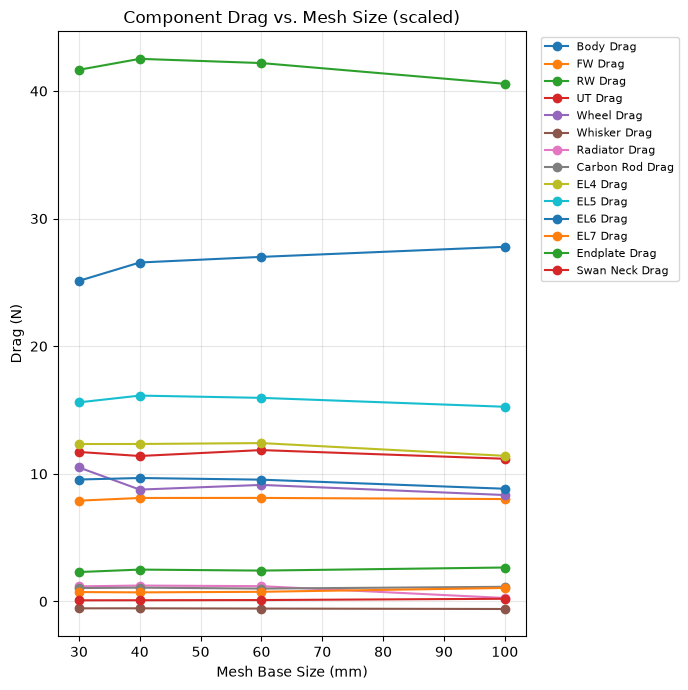

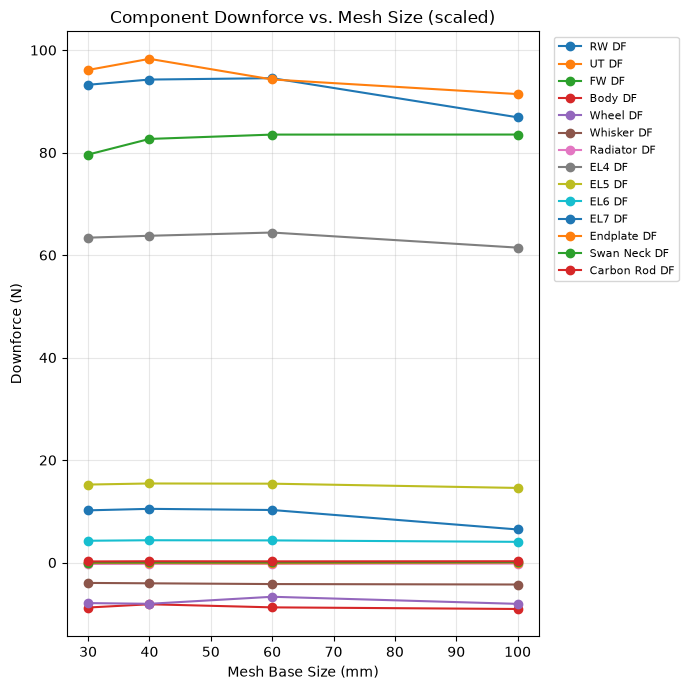

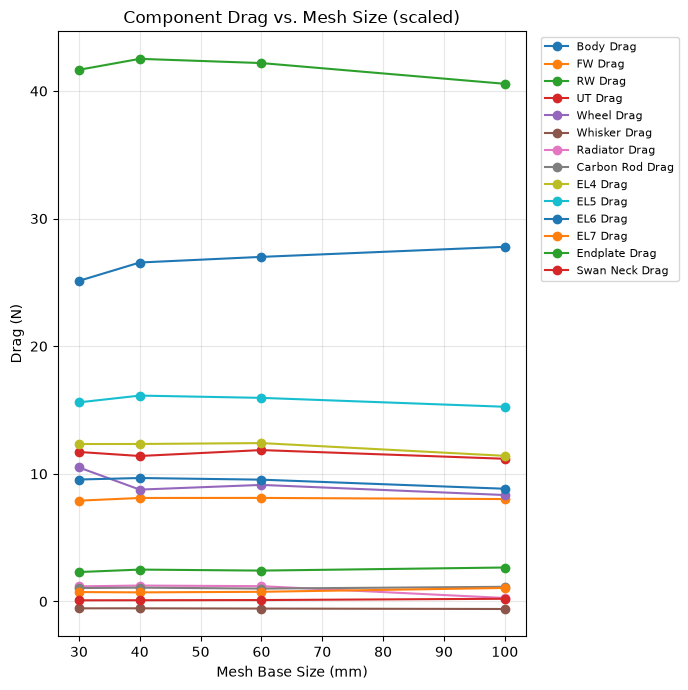

In [8]:
# Plot 1: component downforce
plot_component_group(df_components, 'Downforce (N)', 'Component Downforce vs. Mesh Size (scaled)', 'plot_df_components.png')

# Plot 2: component drag
plot_component_group(drag_components, 'Drag (N)', 'Component Drag vs. Mesh Size (scaled)', 'plot_drag_components.png')

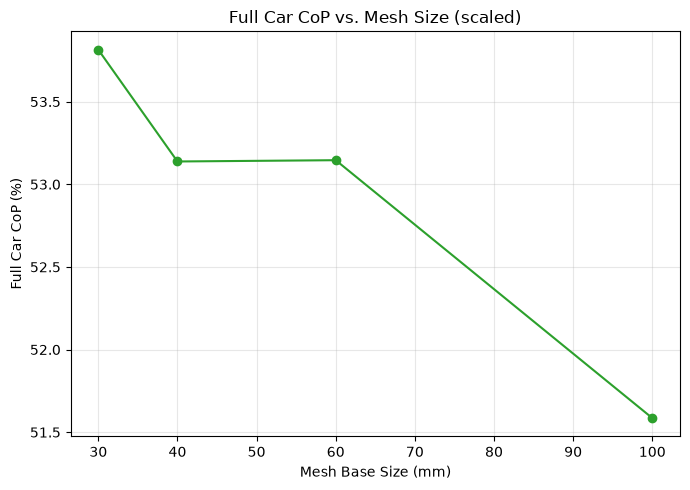

In [9]:
# Plot 3: CoP%
fig_cop, ax_cop = plt.subplots(figsize=(7, 5))
ax_cop.plot(x, raw_df.loc['Full Car CoP', mesh_order], marker='o', color='tab:green')
ax_cop.set_xlabel('Mesh Base Size (mm)')
ax_cop.set_ylabel('Full Car CoP (%)')
ax_cop.set_title('Full Car CoP vs. Mesh Size (scaled)')
ax_cop.grid(alpha=0.3)
fig_cop.tight_layout()
fig_cop.savefig(DATA_DIR / 'plot_cop_percentage.png', dpi=150)

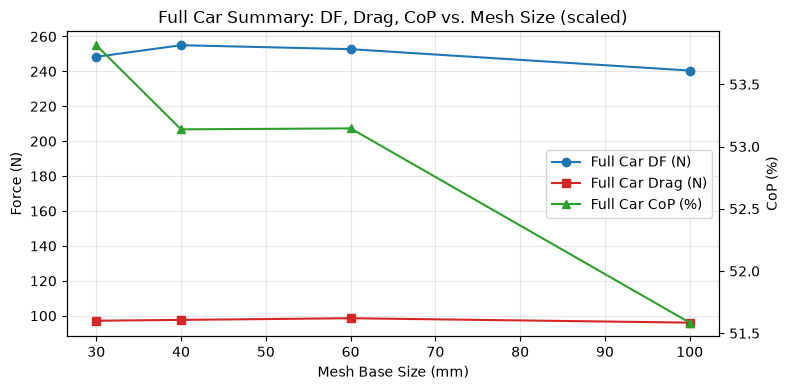

In [10]:
# Plot 4: Full Car DF + Drag (N, left axis) and Full Car CoP (%, right axis)
fig_summary, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(x, raw_df.loc['Full Car DF', mesh_order], marker='o', color='tab:blue', label='Full Car DF (N)')
ax1.plot(x, raw_df.loc['Full Car Drag', mesh_order], marker='s', color='tab:red', label='Full Car Drag (N)')
ax1.set_xlabel('Mesh Base Size (mm)')
ax1.set_ylabel('Force (N)')
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(x, raw_df.loc['Full Car CoP', mesh_order], marker='^', color='tab:green', label='Full Car CoP (%)')
ax2.set_ylabel('CoP (%)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best')
ax1.set_title('Full Car Summary: DF, Drag, CoP vs. Mesh Size (scaled)')
fig_summary.tight_layout()
fig_summary.savefig(DATA_DIR / 'plot_full_car_summary.png', dpi=150)

## 4) Calculate & Plot Deltas
% delta = (mesh - baseline) / |baseline| * 100

The baseline is `BASELINE_COL` (30mm), the finest mesh.

In [11]:
baseline_col = BASELINE_COL
baseline_vals = raw_df[baseline_col]

delta_df = pd.DataFrame(index=raw_df.index)
for col in ordered_cols:
    if col == baseline_col:
        continue
    delta_df[f'{col} vs {baseline_col} (%)'] = (raw_df[col] - baseline_vals) / baseline_vals.abs() * 100

delta_df.loc[['Full Car DF', 'Full Car Drag', 'Full Car CoP', 'ClA', 'CdA', 'Cell Count']].round(2)

,40mm vs 30mm (%),60mm vs 30mm (%),100mm vs 30mm (%)
Metric,,,
Full Car DF,2.68,1.76,-3.17
Full Car Drag,0.51,1.49,-1.11
Full Car CoP,-1.26,-1.24,-4.14
ClA,-2.68,-1.76,3.17
CdA,0.51,1.49,-1.11
Cell Count,-45.70,-76.66,-91.51


In [12]:
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '<', '>', 'p', '*', 'h', 'H', '8', 'd']
linestyles = ['-', '--', '-.', ':']

Excluded from DF % plot: ['Endplate DF', 'Swan Neck DF']
Excluded from Drag % plot: ['Endplate Drag', 'Swan Neck Drag']


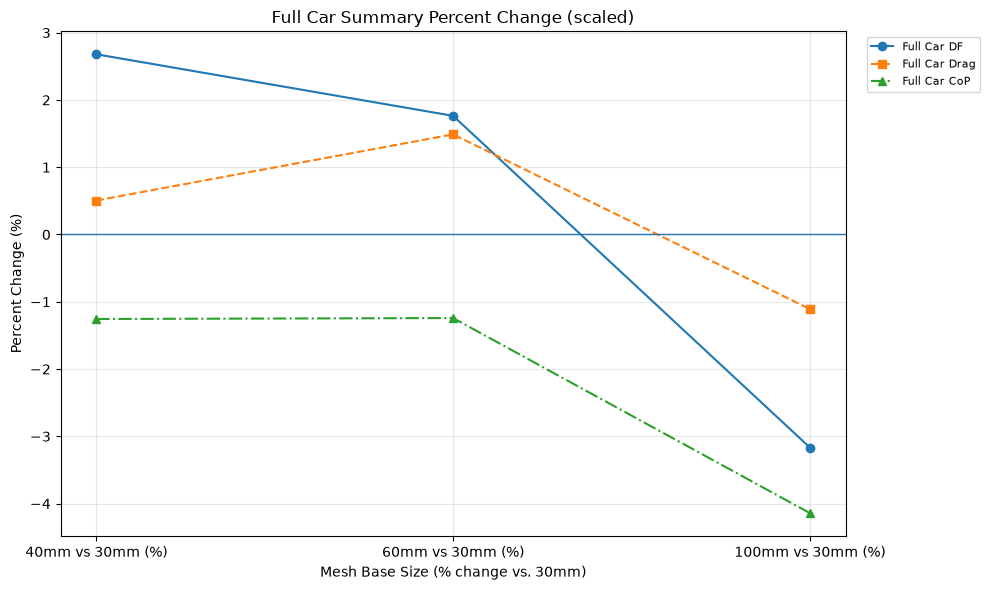

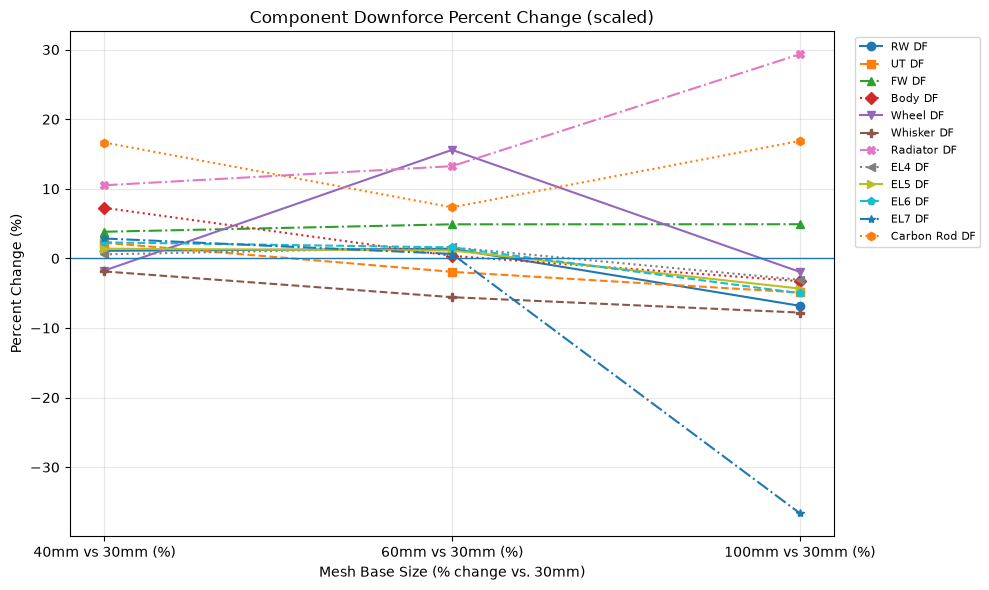

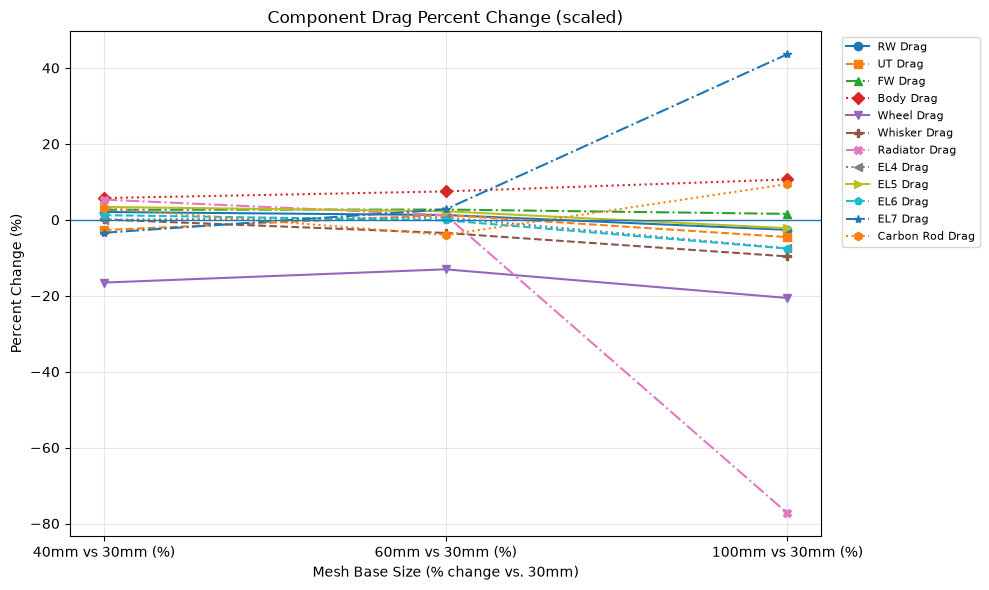

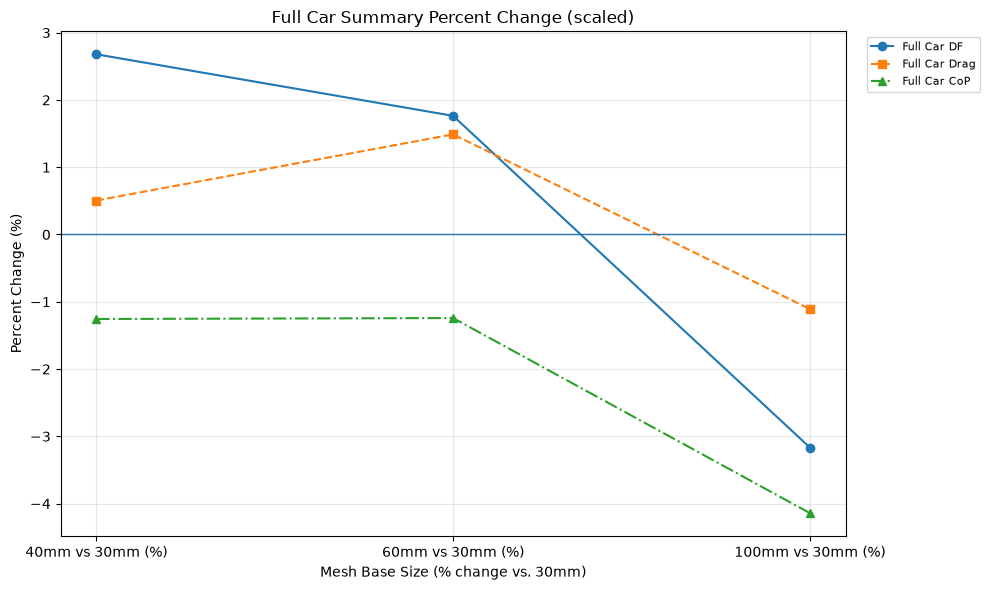

In [13]:
# Components whose baseline force is under 0.1 N are excluded from the percent-change plot:
# tiny absolute noise gives huge percent changes that hide the other components.
# Here that is Endplate DF (~0.09 N) and Swan Neck DF (~0.02 N).
NEAR_ZERO_N = 0.1
df_components_pct = [m for m in df_components if abs(baseline_vals[m]) >= NEAR_ZERO_N]
print('Excluded from DF % plot:', [m for m in df_components if m not in df_components_pct])

# Drag % plot uses the same components as the DF % plot, in the same order, so each
# component keeps the same marker / line style on both plots
drag_components_pct = [m.replace(' DF', ' Drag') for m in df_components_pct
                       if m.replace(' DF', ' Drag') in drag_components]
print('Excluded from Drag % plot:', [m for m in drag_components if m not in drag_components_pct])


def plot_delta_group(metrics, title, filename, marker_list=None):
    fig, ax = plt.subplots(figsize=(10, 6))
    for i, metric in enumerate(metrics):
        ax.plot(
            delta_df.columns,
            delta_df.loc[metric],
            marker=(marker_list or markers)[i],
            linestyle=linestyles[i % len(linestyles)],
            label=metric
        )
    ax.axhline(0, linewidth=1)
    ax.set_xlabel(f'Mesh Base Size (% change vs. {baseline_col})')
    ax.set_ylabel('Percent Change (%)')
    ax.set_title(title)
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(DATA_DIR / filename, dpi=150, bbox_inches='tight')
    return fig


# Plot 1: Component Downforce percent delta
plot_delta_group(df_components_pct, 'Component Downforce Percent Change (scaled)', 'plot_delta_df_components.png')

# Plot 2: Component Drag percent delta
plot_delta_group(drag_components_pct, 'Component Drag Percent Change (scaled)', 'plot_delta_drag_components.png')

# Plot 3: Full Car summary percent delta
plot_delta_group(['Full Car DF', 'Full Car Drag', 'Full Car CoP'], 'Full Car Summary Percent Change (scaled)',
                 'plot_delta_full_car_summary.png', marker_list=['o', 's', '^'])

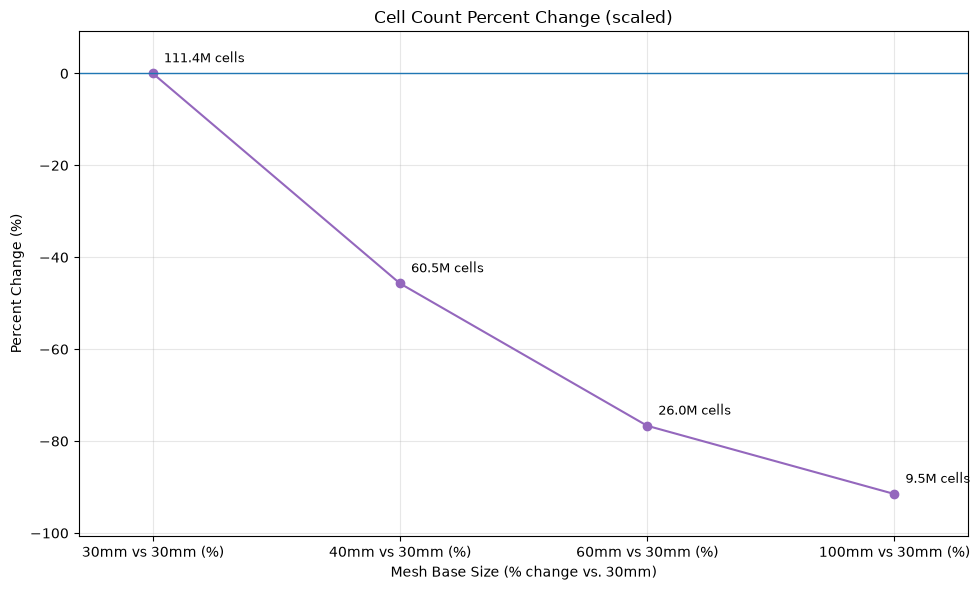

In [14]:
# Plot 4: Cell Count percent delta, including the baseline itself (0%) so its cell count is shown too
cell_pct = pd.concat([
    pd.Series({f'{baseline_col} vs {baseline_col} (%)': 0.0}),
    delta_df.loc['Cell Count'],
])

fig_cellcount_delta, ax_cellcount_delta = plt.subplots(figsize=(10, 6))
ax_cellcount_delta.plot(cell_pct.index, cell_pct.values, marker='o', color='tab:purple')
ax_cellcount_delta.axhline(0, linewidth=1)

# label each point with its absolute cell count
for i, col in enumerate(cell_pct.index):
    mesh_col = col.split(' vs ')[0]
    ax_cellcount_delta.annotate(f"{raw_df.loc['Cell Count', mesh_col] / 1e6:.1f}M cells",
                                (i, cell_pct[col]),
                                textcoords='offset points', xytext=(8, 8), fontsize=9)
ax_cellcount_delta.set_xlabel(f'Mesh Base Size (% change vs. {baseline_col})')
ax_cellcount_delta.set_ylabel('Percent Change (%)')
ax_cellcount_delta.set_title('Cell Count Percent Change (scaled)')
ax_cellcount_delta.margins(x=0.1, y=0.1)
ax_cellcount_delta.grid(alpha=0.3)
fig_cellcount_delta.tight_layout()
fig_cellcount_delta.savefig(DATA_DIR / 'plot_delta_cell_count.png', dpi=150, bbox_inches='tight')

## 5) Comparison with the Original (Unscaled) Study
Checks whether the meshing fix worked: the cell count should now respond strongly to base size. Downforce in the original reports already reads positive, and the shared parser handles both conventions.

Original                                            \
                       30mm          35mm          40mm          50mm   
Cell Count     3.909425e+07  3.749048e+07  3.684016e+07  3.573162e+07   
Full Car DF    2.439825e+02  2.484418e+02  2.445639e+02  2.431410e+02   
Full Car Drag  9.253686e+01  9.494198e+01  9.286285e+01  9.413411e+01   
Full Car CoP   4.785134e+01  4.889029e+01  4.909073e+01  4.919757e+01   

                                   Scaled                              \
                       60mm          30mm          40mm          60mm   
Cell Count     3.474150e+07  1.113830e+08  6.048351e+07  2.599481e+07   
Full Car DF    2.458907e+02  2.483410e+02  2.549939e+02  2.527214e+02   
Full Car Drag  9.502966e+01  9.713344e+01  9.762410e+01  9.857940e+01   
Full Car CoP   4.958220e+01  5.381425e+01  5.313820e+01  5.314596e+01   

                             
                      100mm  
Cell Count     9.460927e+06  
Full Car DF    2.404775e+02  
Full Car Drag  9.605687e+01  
Full Car CoP   5.158554e+01

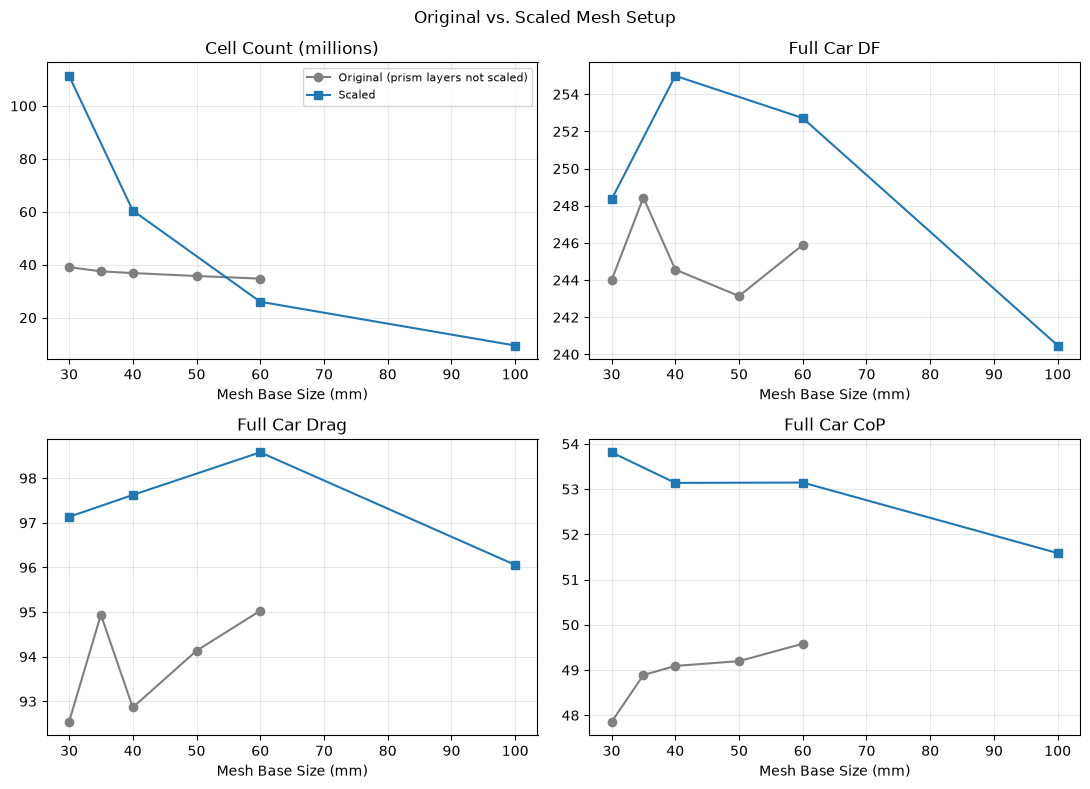

In [15]:
orig_records, _, _, orig_sizes = load_reports(ORIGINAL_DIR, 'force_reports_*mm.txt')
orig_order = sorted(orig_records, key=lambda c: orig_sizes[c])
orig_df = pd.DataFrame(orig_records)[orig_order]

compare_metrics = ['Cell Count', 'Full Car DF', 'Full Car Drag', 'Full Car CoP']
fig_cmp, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, metric in zip(axes.flat, compare_metrics):
    scale = 1e6 if metric == 'Cell Count' else 1
    ax.plot([orig_sizes[c] for c in orig_order], orig_df.loc[metric, orig_order] / scale,
            marker='o', color='tab:gray', label='Original (prism layers not scaled)')
    ax.plot(x, raw_df.loc[metric, mesh_order] / scale, marker='s', color='tab:blue', label='Scaled')
    ax.set_title(metric + (' (millions)' if scale != 1 else ''))
    ax.set_xlabel('Mesh Base Size (mm)')
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig_cmp.suptitle('Original vs. Scaled Mesh Setup')
fig_cmp.tight_layout()
fig_cmp.savefig(DATA_DIR / 'plot_compare_original_vs_scaled.png', dpi=150)

compare_df = pd.concat(
    {'Original': orig_df.loc[compare_metrics], 'Scaled': raw_df.loc[compare_metrics]}, axis=1
)
compare_df

# Wall Time
Cost side of the study. Source: `mesh_walltime_summary_scaled.xlsx` (file mtimes from the cluster, not PBS accounting).

**Caveats:**
- **Iterations Run and Cores Used are estimates** (highlighted yellow in the sheet; see the cell comments there).
- The runs used **different core counts**, so cost is compared with **core-seconds per iteration** (solve time / iteration x cores). Wall-clock time per iteration is not comparable.
- 40/60/100mm ran concurrently on 2026-10-04 (shared cluster load).

## 6) Load Wall Time Table

In [16]:
wall_raw = pd.read_excel(WALLTIME_XLSX)

# Sheet has footnote rows under the table; keep only rows whose first column is a mesh size
size_col = 'Mesh Base Size (mm)'
wall_raw[size_col] = pd.to_numeric(wall_raw[size_col], errors='coerce')
wall_raw = wall_raw.dropna(subset=[size_col])

# Durations are recomputed from the raw timestamps instead of read from the sheet's formula
# columns, which have no cached values until the file has been saved once in Excel.
start = pd.to_datetime(wall_raw['Start Time'])
solve_end = pd.to_datetime(wall_raw['Solve End Time'])
done = pd.to_datetime(wall_raw['Job Complete Time'])
iters = wall_raw['Iterations Run'].astype(int)
cores = wall_raw['Cores Used (machinefile)'].astype(int)
solve_s = (solve_end - start).dt.total_seconds()

wall_df = pd.DataFrame({
    'Iterations Run': iters,
    'Cores Used': cores,
    'Solve Time (min)': solve_s / 60,
    'Post-Processing Time (min)': (done - solve_end).dt.total_seconds() / 60,
    'Total Wall Time (min)': (done - start).dt.total_seconds() / 60,
    'Solve Time / Iteration (s)': solve_s / iters,
    'Core-Seconds / Iteration': solve_s / iters * cores,
    'Core-Hours': (done - start).dt.total_seconds() / 3600 * cores,
})
wall_df.index = [f'{int(s)}mm' for s in wall_raw[size_col]]  # same keys as raw_df columns
wall_df.index.name = 'Mesh Size'

missing = set(mesh_order) ^ set(wall_df.index)
if missing:
    print(f'WARNING: mesh sizes only in one of force reports / wall time: {missing}')

wall_df = wall_df.loc[mesh_order]
wall_df['Cell Count (M)'] = raw_df.loc['Cell Count', mesh_order] / 1e6
wall_df.round(2)

,Iterations Run,Cores Used,Solve Time (min),Post-Processing Time (min),Total Wall Time (min),Solve Time / Iteration (s),Core-Seconds / Iteration,Core-Hours,Cell Count (M)
Mesh Size,,,,,,,,,
30mm,700,127,106.60,4.68,111.28,9.14,1160.42,235.55,111.38
40mm,900,95,78.92,16.82,95.73,5.26,499.81,151.58,60.48
60mm,600,63,43.42,16.43,59.85,4.34,273.53,62.84,25.99
100mm,1250,15,116.23,14.55,130.78,5.58,83.69,32.70,9.46


## 7) Derived Columns
% change vs. the baseline (30mm), same convention as the force deltas.

In [17]:
wall_base = wall_df.loc[baseline_col]

wall_delta_df = pd.DataFrame(index=wall_df.index)
for c in ['Core-Seconds / Iteration', 'Core-Hours', 'Cell Count (M)']:
    wall_delta_df[f'{c} vs {baseline_col} (%)'] = (wall_df[c] - wall_base[c]) / wall_base[c] * 100

wall_delta_df = wall_delta_df.drop(index=baseline_col)
wall_delta_df.round(2)

,Core-Seconds / Iteration vs 30mm (%),Core-Hours vs 30mm (%),Cell Count (M) vs 30mm (%)
Mesh Size,,,
40mm,-56.93,-35.65,-45.70
60mm,-76.43,-73.32,-76.66
100mm,-92.79,-86.12,-91.51


## 8) Plot Wall Time

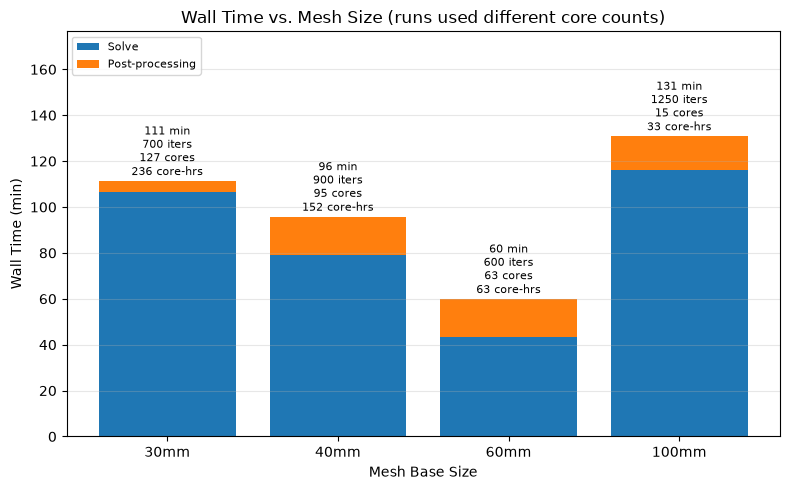

In [18]:
# Plot 1: Wall time by mesh size (solve + post-processing), iterations / cores / core-hours annotated
fig_wall, ax_wall = plt.subplots(figsize=(8, 5))
xpos = range(len(mesh_order))

ax_wall.bar(xpos, wall_df['Solve Time (min)'], color='tab:blue', label='Solve')
ax_wall.bar(xpos, wall_df['Post-Processing Time (min)'], bottom=wall_df['Solve Time (min)'],
            color='tab:orange', label='Post-processing')

for i, col in enumerate(mesh_order):
    r = wall_df.loc[col]
    ax_wall.text(i, r['Total Wall Time (min)'] + 1,
                 f"{r['Total Wall Time (min)']:.0f} min\n{r['Iterations Run']:.0f} iters\n"
                 f"{r['Cores Used']:.0f} cores\n{r['Core-Hours']:.0f} core-hrs",
                 ha='center', va='bottom', fontsize=8)

ax_wall.set_xticks(list(xpos))
ax_wall.set_xticklabels(mesh_order)
ax_wall.set_ylim(0, wall_df['Total Wall Time (min)'].max() * 1.35)
ax_wall.set_xlabel('Mesh Base Size')
ax_wall.set_ylabel('Wall Time (min)')
ax_wall.set_title('Wall Time vs. Mesh Size (runs used different core counts)')
ax_wall.legend(loc='upper left', fontsize=8)
ax_wall.grid(alpha=0.3, axis='y')
fig_wall.tight_layout()
fig_wall.savefig(DATA_DIR / 'plot_walltime.png', dpi=150)

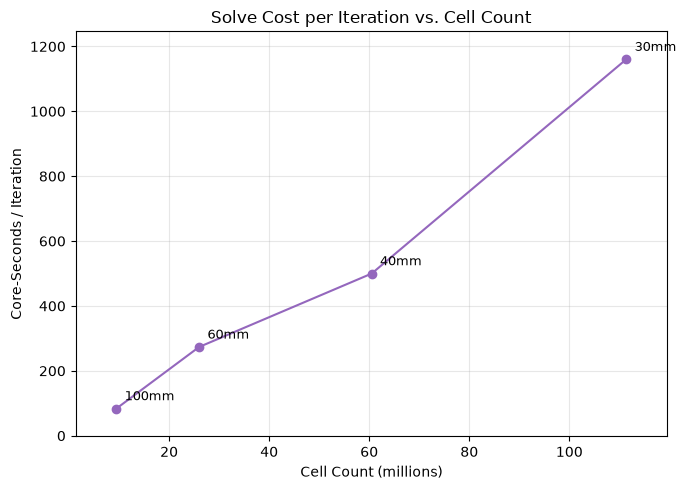

In [19]:
# Plot 2: Cost per iteration (core-seconds) vs. cell count
fig_tpi, ax_tpi = plt.subplots(figsize=(7, 5))
ax_tpi.plot(wall_df['Cell Count (M)'], wall_df['Core-Seconds / Iteration'], marker='o', color='tab:purple')

for col in mesh_order:
    ax_tpi.annotate(col, (wall_df.loc[col, 'Cell Count (M)'], wall_df.loc[col, 'Core-Seconds / Iteration']),
                    textcoords='offset points', xytext=(6, 6), fontsize=9)

ax_tpi.margins(x=0.08, y=0.08)
ax_tpi.set_xlabel('Cell Count (millions)')
ax_tpi.set_ylabel('Core-Seconds / Iteration')
ax_tpi.set_title('Solve Cost per Iteration vs. Cell Count')
ax_tpi.grid(alpha=0.3)
fig_tpi.tight_layout()
fig_tpi.savefig(DATA_DIR / 'plot_time_per_iteration.png', dpi=150)

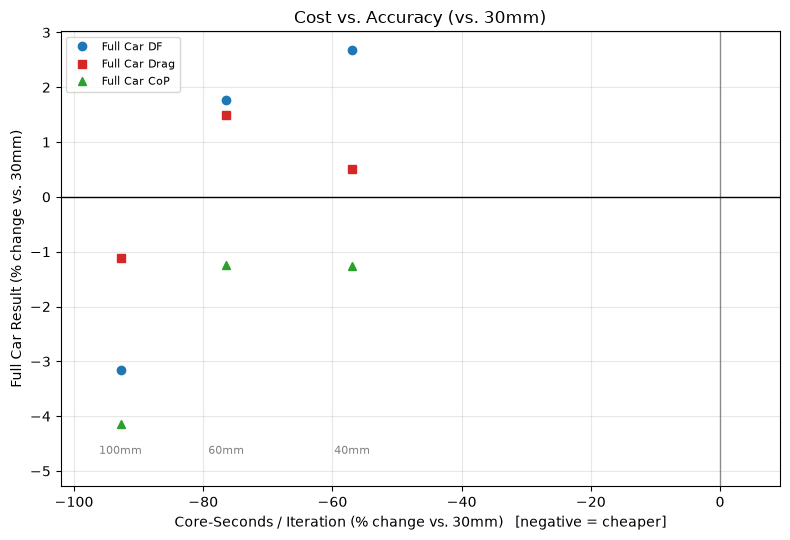

In [20]:
# Plot 3: Cost vs. accuracy. x = change in cost per iteration vs. baseline, y = how far the
# full car results drift from the baseline. Each point is one non-baseline mesh size.
cost_col = f'Core-Seconds / Iteration vs {baseline_col} (%)'
sizes_plot = wall_delta_df.index

fig_ca, ax_ca = plt.subplots(figsize=(8, 5.5))
for i, (metric, color) in enumerate([('Full Car DF', 'tab:blue'), ('Full Car Drag', 'tab:red'), ('Full Car CoP', 'tab:green')]):
    y = [delta_df.loc[metric, f'{s} vs {baseline_col} (%)'] for s in sizes_plot]
    ax_ca.plot(wall_delta_df[cost_col], y, marker=markers[i], color=color, linestyle='none', label=metric)

# Label each mesh size in a strip below the data
ymin, ymax = ax_ca.get_ylim()
ax_ca.set_ylim(ymin - 0.8, ymax)
ax_ca.margins(x=0.1)
for s in sizes_plot:
    ax_ca.annotate(s, (wall_delta_df.loc[s, cost_col], ymin - 0.05), va='top', ha='center', fontsize=8, color='gray')

ax_ca.axhline(0, linewidth=1, color='k')
ax_ca.axvline(0, linewidth=1, color='k', alpha=0.4)
ax_ca.set_xlabel(f'Core-Seconds / Iteration (% change vs. {baseline_col})   [negative = cheaper]')
ax_ca.set_ylabel(f'Full Car Result (% change vs. {baseline_col})')
ax_ca.set_title(f'Cost vs. Accuracy (vs. {baseline_col})')
ax_ca.legend(loc='best', fontsize=8)
ax_ca.grid(alpha=0.3)
fig_ca.tight_layout()
fig_ca.savefig(DATA_DIR / 'plot_cost_vs_accuracy.png', dpi=150)

## Export
Writes `mesh_study_results_scaled.xlsx` with `Raw Values`, `Percent Delta`, `Original vs Scaled` and `Wall Time` sheets.

In [21]:
from openpyxl.utils import get_column_letter

with pd.ExcelWriter(OUTPUT_XLSX, engine='openpyxl') as writer:
    raw_df.to_excel(writer, sheet_name='Raw Values')
    delta_df.to_excel(writer, sheet_name='Percent Delta')
    compare_df.to_excel(writer, sheet_name='Original vs Scaled')
    wall_df.join(wall_delta_df).to_excel(writer, sheet_name='Wall Time')

    for sheet_name in ['Raw Values', 'Percent Delta', 'Original vs Scaled', 'Wall Time']:
        ws = writer.sheets[sheet_name]
        ws.column_dimensions['A'].width = 26
        for i in range(2, ws.max_column + 1):
            ws.column_dimensions[get_column_letter(i)].width = 18

print(f'Wrote {OUTPUT_XLSX.resolve()}')

Wrote /Users/amyliu/Desktop/BFR/BFR Vault/B27 Studies/mesh-base-study/scaled/mesh_study_results_scaled.xlsx
